In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
if 'google.colab' in str(get_ipython()):
    print("Google Colab 環境を検出しました。環境構築を開始します...")
    if not os.path.exists("study-mikanos"):
        !git clone https://github.com/miyayudai/study-mikanos.git
    %cd study-mikanos
    !pip install -q -r requirements.txt
    !pip install -q -e .
    !cmake -B build -S . > /dev/null && cmake --build build --target ch03_error_handling_sim > /dev/null
    print("セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    print("ローカル実行環境です。")


ローカル実行環境です。


# 3.6 エラー処理をしよう (`Error Handling`) & コラム3.2 ポインタのキャスト (`Pointer Casts`)
## 『ゼロからのOS自作入門』 第3章 画面表示の練習とブートローダ (`osbook_day03d`)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/3/3.6_Error_Handling_and_Pointer_Casts.ipynb)

---

### 🎯 本節の学習目標 (Learning Objectives)
1. **サイレントクラッシュの撲滅とエラー処理の必然性**: 前節までのブートローダが抱えていた「戻り値を無視して失敗時に黒画面のままハングアップする危険性」を理解し、OSブートローダにおける厳格な多層防御の動機を掴む。
2. **UEFI 仕様における `EFI_STATUS` のビット構造**: 64ビット整数における最上位ビット (**MSB, Bit 63: Error Bit**) と下位 63ビットの状態コード番号のレイアウトを理解する。
3. **`EFI_ERROR` マクロの数理と x86-64 符号付き判定**: 2の補数表現における負数判定 `(((INTN)(Status)) < 0)` の代数的原理と、CPU がたった1クロックの条件分岐（`TEST` / `JS`）でエラーを判定できるハードウェア的理由を導出する。
4. **EDK II `Print(L"%r")` によるエラー可視化**: `%r` 書式指定子がステータス数値を人間可読な文字列（`EFI_SUCCESS`, `EFI_NOT_FOUND`, `EFI_BUFFER_TOO_SMALL` 等）に変換する仕組みを学ぶ。
5. **障害耐性 (Graceful Degradation) の設計思想**: `\memmap` のオープン失敗を `Halt()` せずに「無視して続行（Ignored.）」する理由を工学的に解明する。
6. **`HLT` 特権命令と CPU 省電力状態**: 無限ループ `while(1);` が引き起こす CPU 100% 負荷・過熱問題を回避し、`while(1) __asm__("hlt");` で CPU クロックを停止して割り込みを待つ `Halt()` 関数の低レイヤ機構を学ぶ。
7. **コラム 3.2 ポインタのキャストとモダン C++**: C言語スタイルキャスト `(Type)expr` の危険性と、モダン C++ の 4大キャスト（`static_cast`, `reinterpret_cast`, `const_cast`, `dynamic_cast`）の型安全性モデル、および OS 自作における `reinterpret_cast` の不可欠性をマスターする。


## 1. なぜエラー処理が必要なのか？（サイレントクラッシュの恐怖と動機）

### 1.1 前節（osbook_day03c）までのブートローダが抱えていた脆弱性
前節までの `MikanLoaderPkg/Main.c` では、UEFI ファームウェアが提供する様々な API 関数を呼び出していましたが、**その戻り値（`EFI_STATUS`）を一切チェックしていませんでした**。

```c
// osbook_day03c における無防備な呼び出しの例:
GetMemoryMap(&memmap);               // もしバッファ不足で失敗したら？ -> memmap は未初期化のゴミデータ
OpenRootDir(image_handle, &root_dir);// ルートディレクトリが開けなかったら？ -> root_dir は nullptr
root_dir->Open(..., L"\kernel.elf");// USB内に kernel.elf が存在しなかったら？ -> kernel_file は無効
gBS->AllocatePages(...);             // メモリ不足で 0x100000 が確保できなかったら？
kernel_file->Read(...);              // ファイル読み込みが失敗したら？
gBS->ExitBootServices(...);          // MapKey 不一致で失敗したら？
```

もし上記のいずれか1つでも失敗した場合、何が起きるでしょうか？

1. **サイレントクラッシュ (Silent Crash)**:
   エラーの発生を検知できないまま処理が進み、`0x100000` にあるはずのカーネルバイナリが存在しない状態で `entry_point(...)` を実行します。
2. **CPU の例外暴走と黒画面ハング (Black Screen Hang)**:
   CPU はゴミデータを機械語命令としてフェッチしようとし、直ちに **未定義命令例外 (#UD)** や **一般保護例外 (#GP)** を発生させて停止します。画面には何も表示されず、PC は黒い画面のまま完全に沈黙します。
3. **デバッグの絶望**:
   「USBメモリの接触不良か？」「ファイル名の間違いか？」「メモリの競合か？」「カーネルのコードが間違っているのか？」——原因の切り分けが不可能になり、何時間も無駄にすることになります。

### 1.2 堅牢な OS ブートローダの条件
OS ブートローダ（Loader）は、ハードウェアと OS カーネルをつなぐ唯一の架け橋です。したがって、以下の 2 大原則を厳格に順守しなければなりません：

1. **すべての外部 API 呼び出しでステータスを即時検査する**:
   戻り値を変数 `EFI_STATUS status` に受け、直後にマクロ `EFI_ERROR(status)` で成否を判定する。
2. **失敗時は「原因の文字列表示」と「CPUの安全な停止」を行う**:
   人間が見て即座に原因を把握できるようにエラーメッセージ（`Print(L"failed to ...: %r
", status)`）を表示した上で、CPU を低消費電力状態で安全に停止（`Halt()`）させる。


Saved figure to: 3/result/fig3_11_uefi_status_and_error_handling_flow.png


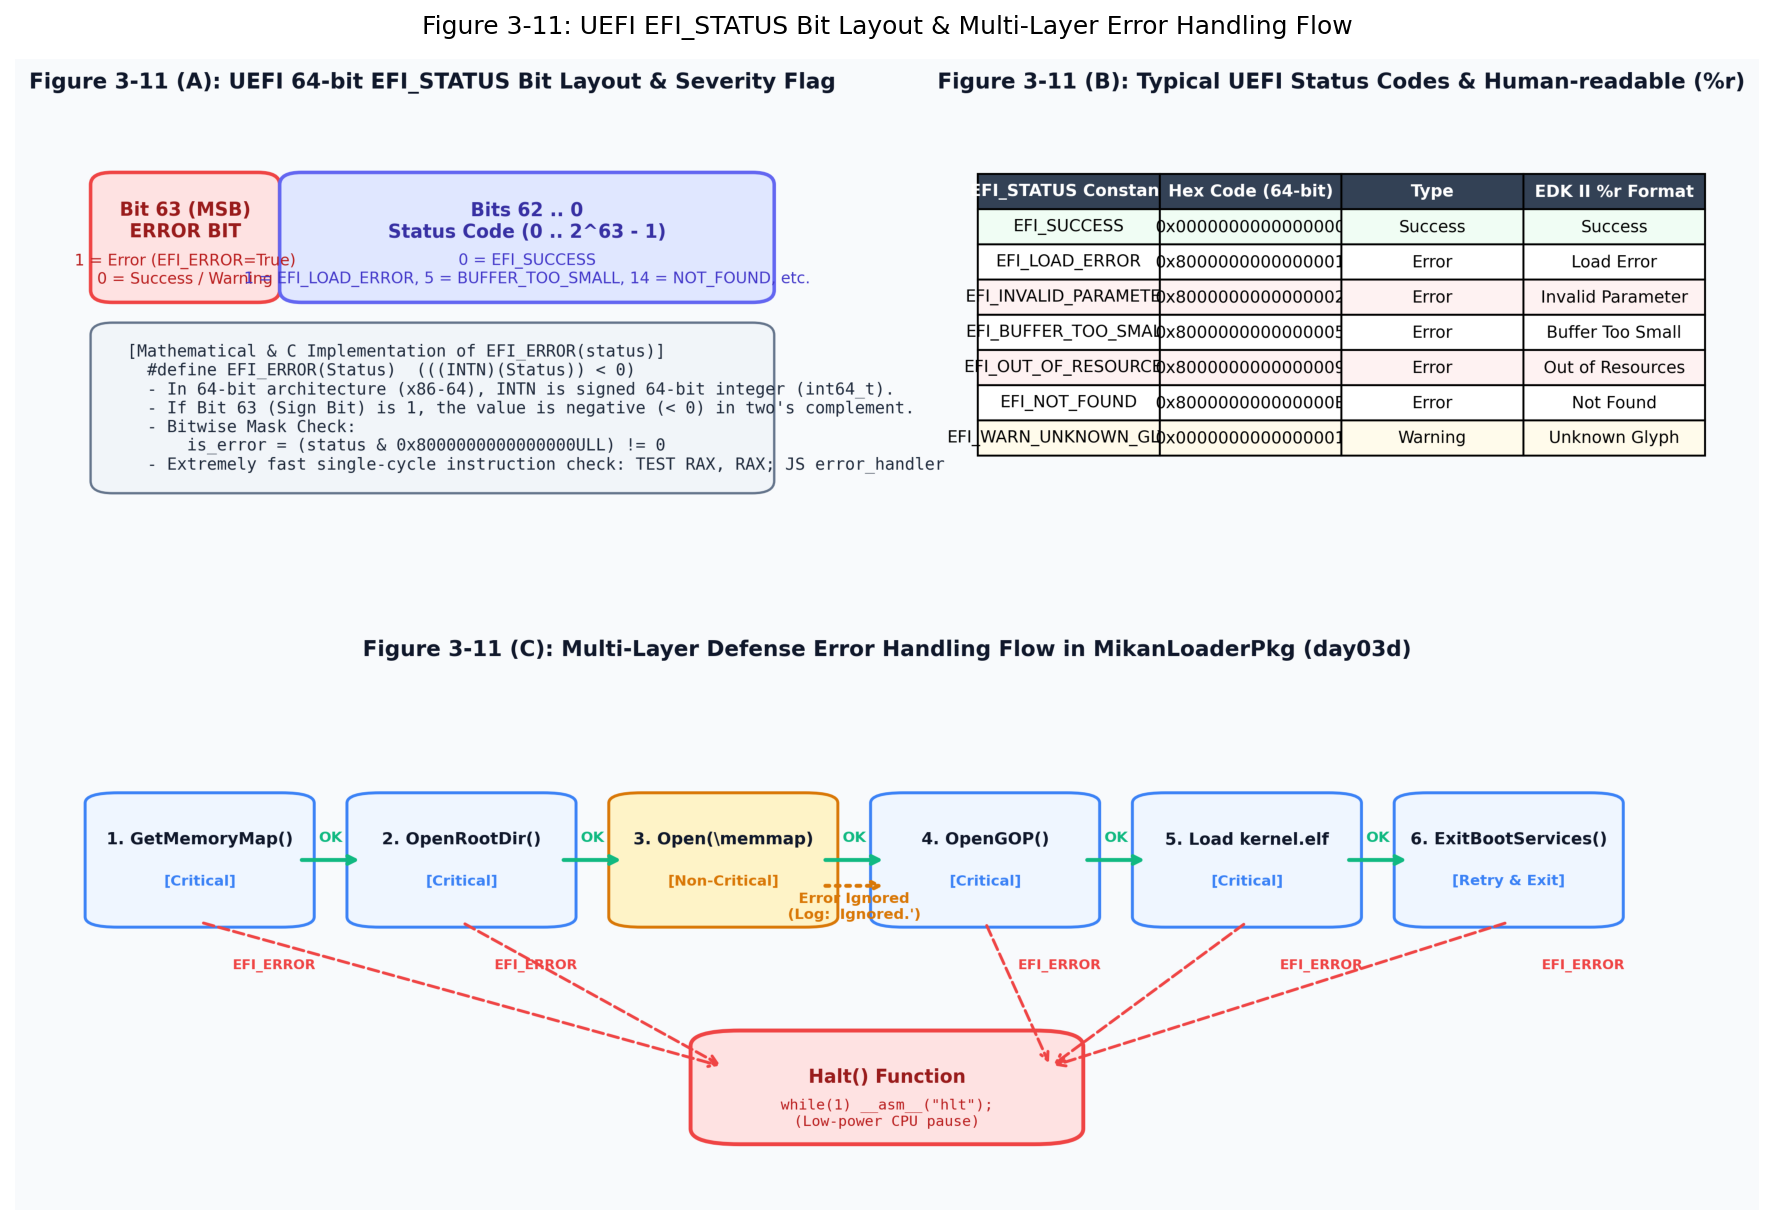

In [2]:
# === EFI_STATUS 64ビット構造とブートローダ多層エラーハンドリング制御フロー (fig3_11) ===
import os
import matplotlib.pyplot as plt
from PIL import Image
from common import plot_uefi_status_and_error_handling_flow

target_dir = "3/result" if os.path.exists("3/result") else "result"
fig11_path = plot_uefi_status_and_error_handling_flow(f"{target_dir}/fig3_11_uefi_status_and_error_handling_flow.png")
print("Saved figure to:", fig11_path)

plt.figure(figsize=(15, 10), dpi=150)
img = Image.open(fig11_path)
plt.imshow(img)
plt.axis("off")
plt.title("Figure 3-11: UEFI EFI_STATUS Bit Layout & Multi-Layer Error Handling Flow", fontsize=12, pad=12)
plt.show()


## 2. UEFI 仕様における `EFI_STATUS` のビット構造と `EFI_ERROR` マクロの数理

### 2.1 64ビット `EFI_STATUS` のビットレイアウト
UEFI Specification において、`EFI_STATUS` はポインタと同じサイズを持つ符号なし整数（`UINTN`、x86-64 では 64ビット `uint64_t`）として定義されています。

そのビット構造は、上位 1 ビットの**重大度フラグ（Severity Flag）**と、下位 63 ビットの**ステータスコード番号**に明確に二分されています：

| ビット範囲 | フィールド名 | 意味 | 値の定義 |
|:---:|:---:|---|---|
| **Bit 63 (MSB)** | **ERROR BIT** | エラーフラグ | `1`: エラー発生 (`EFI_ERROR == True`)<br>`0`: 正常終了または警告 |
| **Bits 62 .. 0** | **Status Code** | 具体的な状態番号 | `0`: `EFI_SUCCESS`<br>`1`: `EFI_LOAD_ERROR`<br>`2`: `EFI_INVALID_PARAMETER`<br>`5`: `EFI_BUFFER_TOO_SMALL`<br>`9`: `EFI_OUT_OF_RESOURCES`<br>`14` (`0xE`): `EFI_NOT_FOUND` 等 |

### 2.2 `EFI_ERROR` マクロの数理導出（2の補数表現と高速判定）
EDK II のヘッダ（`Base.h`）では、マクロ `EFI_ERROR` が以下のように定義されています：

```c
#define EFI_ERROR(Status)  (((INTN)(Status)) < 0)
```

一見すると「負数かどうかをチェックしているだけ」に見えますが、ここには **2の補数表現 (Two's Complement)** とハードウェアアーキテクチャの巧みな数理が組み込まれています。

#### 数理的証明:
x86-64 において、`INTN` は 64ビット符号付き整数（`int64_t`）です。
最上位ビット（Bit 63）は符号ビット（Sign Bit）であり、2の補数表現では次のように値を表します：

$$X = -b_{63} \cdot 2^{63} + \sum_{i=0}^{62} b_i \cdot 2^i$$

- **エラー発生時 ($b_{63} = 1$)**:
  最上位ビットが 1 であるため、下位ビットがどのような値であっても $X$ は常に負数（$X < 0$）となります。
  $$	ext{EFI\_ERROR}(Status) = 	ext{True}$$
- **正常終了・警告時 ($b_{63} = 0$)**:
  最上位ビットが 0 であるため、$X$ は 0 以上の正数またはゼロ（$X \ge 0$）となります。
  $$	ext{EFI\_ERROR}(Status) = 	ext{False}$$

#### x86-64 アセンブリ命令レベルでのメリット:
ビットマスク比較 `(Status & 0x8000000000000000ULL) != 0` を行う場合、64ビットの即値マスクをレジスタにロードするか、`BT` (Bit Test) 命令を使う必要があります。
しかし、符号付きの `< 0` 判定であれば、CPU のフラグレジスタにおける **SF (Sign Flag: 符号フラグ)** を直接利用できます：

```nasm
; C言語: if (EFI_ERROR(status)) { goto error_handler; }
test  rax, rax      ; RAX (status) の符号ビットを評価し、SF フラグを更新 (1クロック)
js    error_handler ; Jump if Sign (SF == 1, つまり負数の場合にジャンプ)
```
このように、コンパイラは余計なマスク定数レジスタを消費せず、たった **1クロック** の極めてコンパクトな命令列でエラーを検知できるのです。

### 2.3 EDK II `Print(L"%r")` によるエラー文字列の自動展開
EDK II の標準出力関数 `Print` には、UEFI 独自のエクステンション書式指定子 **`%r`** が用意されています。

```c
Print(L"failed to open file '\kernel.elf': %r
", status);
// 出力例: failed to open file '\kernel.elf': Not Found
```
`%r` を指定すると、EDK II ライブラリ内部のエラーコードテーブルが参照され、`0x800000000000000E` という難解な16進数が `"Not Found"` という直感的な英語文字列に自動変換されて画面に出力されます。


In [3]:
# === Python による EFIStatus シミュレーションと 64-bit ビット演算検証 ===
from common import EFIStatus, EFI_ERROR_MASK

print("=== 1. UEFI ステータスオブジェクトの生成とビット解析 ===")
st_success = EFIStatus.success()
print(f"EFI_SUCCESS         : raw = 0x{st_success.raw_value:016X}, is_error = {st_success.is_error}, name = '{st_success.name}'")

st_load_err = EFIStatus.error(1)
print(f"EFI_LOAD_ERROR      : raw = 0x{st_load_err.raw_value:016X}, is_error = {st_load_err.is_error}, code = {st_load_err.code_number}, name = '{st_load_err.name}'")

st_not_found = EFIStatus.error(14)
print(f"EFI_NOT_FOUND       : raw = 0x{st_not_found.raw_value:016X}, is_error = {st_not_found.is_error}, code = {st_not_found.code_number}, name = '{st_not_found.name}'")

st_buf_small = EFIStatus.error(5)
print(f"EFI_BUFFER_TOO_SMALL: raw = 0x{st_buf_small.raw_value:016X}, is_error = {st_buf_small.is_error}, code = {st_buf_small.code_number}, name = '{st_buf_small.name}'")

st_warn = EFIStatus(1)  # MSB is 0, code is 1
print(f"EFI_WARN_UNKNOWN_GLYPH: raw = 0x{st_warn.raw_value:016X}, is_warning = {st_warn.is_warning}, is_error = {st_warn.is_error}, name = '{st_warn.name}'")

print("\n=== 2. 2の補数表現 (Two's Complement) による負数判定 (< 0) の検証 ===")
for st in [st_success, st_load_err, st_not_found, st_warn]:
    # 64-bit unsigned を signed int64 に変換
    signed_val = int.from_bytes(st.raw_value.to_bytes(8, "little", signed=False), "little", signed=True)
    is_neg = signed_val < 0
    assert is_neg == st.is_error, "Two's complement check mismatch!"
    print(f"  Status: {st.name:<24} | Signed INTN: {signed_val:>20} | (< 0) => {is_neg}")


=== 1. UEFI ステータスオブジェクトの生成とビット解析 ===
EFI_SUCCESS         : raw = 0x0000000000000000, is_error = False, name = 'EFI_SUCCESS'
EFI_LOAD_ERROR      : raw = 0x8000000000000001, is_error = True, code = 1, name = 'EFI_LOAD_ERROR'
EFI_NOT_FOUND       : raw = 0x800000000000000E, is_error = True, code = 14, name = 'EFI_NOT_FOUND'
EFI_BUFFER_TOO_SMALL: raw = 0x8000000000000005, is_error = True, code = 5, name = 'EFI_BUFFER_TOO_SMALL'
EFI_WARN_UNKNOWN_GLYPH: raw = 0x0000000000000001, is_warning = True, is_error = False, name = 'EFI_WARN_UNKNOWN_GLYPH'

=== 2. 2の補数表現 (Two's Complement) による負数判定 (< 0) の検証 ===
  Status: EFI_SUCCESS              | Signed INTN:                    0 | (< 0) => False
  Status: EFI_LOAD_ERROR           | Signed INTN: -9223372036854775807 | (< 0) => True
  Status: EFI_NOT_FOUND            | Signed INTN: -9223372036854775794 | (< 0) => True
  Status: EFI_WARN_UNKNOWN_GLYPH   | Signed INTN:                    1 | (< 0) => False


## 3. ブートローダ多層防御と Graceful Degradation（\memmap エラー無視）

### 3.1 `MikanLoaderPkg/Main.c` (`osbook_day03d`) の差分解説
書籍第3章 3.6節（`osbook_day03d`）では、ブートローダ内のすべての主要処理にエラーハンドリングが組み込まれました。

```c
// 1. メモリマップ取得のエラー処理
status = GetMemoryMap(&memmap);
if (EFI_ERROR(status)) {
  Print(L"failed to get memory map: %r\n", status);
  Halt();
}

// 2. ルートディレクトリオープンのエラー処理
status = OpenRootDir(image_handle, &root_dir);
if (EFI_ERROR(status)) {
  Print(L"failed to open root directory: %r\n", status);
  Halt();
}

// 3. \memmap ファイルオープンのエラー処理 (★ここが最大の注目点！)
status = root_dir->Open(
    root_dir, &memmap_file, L"\\memmap",
    EFI_FILE_MODE_READ | EFI_FILE_MODE_WRITE | EFI_FILE_MODE_CREATE, 0);
if (EFI_ERROR(status)) {
  Print(L"failed to open file '\\memmap': %r\n", status);
  Print(L"Ignored.\n");
} else {
  status = SaveMemoryMap(&memmap, memmap_file);
  if (EFI_ERROR(status)) {
    Print(L"failed to save memory map: %r\n", status);
    Halt();
  }
  status = memmap_file->Close(memmap_file);
  if (EFI_ERROR(status)) {
    Print(L"failed to close memory map: %r\n", status);
    Halt();
  }
}

// 4. GOP オープンのエラー処理
status = OpenGOP(image_handle, &gop);
if (EFI_ERROR(status)) {
  Print(L"failed to open GOP: %r\n", status);
  Halt();
}

// 5. カーネルファイルオープン・情報取得・メモリ確保・読み込みのエラー処理
status = root_dir->Open(root_dir, &kernel_file, L"\\kernel.elf", EFI_FILE_MODE_READ, 0);
if (EFI_ERROR(status)) {
  Print(L"failed to open file '\\kernel.elf': %r\n", status);
  Halt();
}
...
status = gBS->AllocatePages(AllocateAddress, EfiLoaderData, (kernel_file_size + 0xfff) / 0x1000, &kernel_base_addr);
if (EFI_ERROR(status)) {
  Print(L"failed to allocate pages: %r", status);
  Halt();
}
status = kernel_file->Read(kernel_file, &kernel_file_size, (VOID*)kernel_base_addr);
if (EFI_ERROR(status)) {
  Print(L"error: %r", status);
  Halt();
}
```

### 3.2 障害耐性 (Graceful Degradation): なぜ \memmap の失敗は無視できるのか？
上記のコードの中で、1箇所だけ `Halt()` せずに処理を継続している特別なステップがあります。それが **`root_dir->Open(..., L"\memmap", ...)`** です。

#### 工学的動機と設計思想:
1. **本質的リソース vs 補助的デバッグ情報**:
   - `kernel.elf` や `GOP`、`AllocatePages` は、カーネルを実行するために **1つでも欠けたら OS の起動が不可能な絶対的必須リソース** です。したがって失敗時は即座に停止（`Halt()`）させるのが正しい判断です。
   - 一方、`\memmap` は第2章で導入した「人間がテキストエディタで物理メモリレイアウトを確認するためのデバッグ用ファイル」に過ぎません。
2. **実機環境における書き込み制約**:
   - USBメモリがハードウェア的な書き込み禁止スイッチ（Write-Protect）に入っていたり、FATファイルシステムの容量が満杯（`EFI_VOLUME_FULL`）であったり、あるいは CD-ROM や PXE ネットワークブートなどの読み込み専用メディアから起動した場合、新規ファイルの作成は必ず失敗（`EFI_WRITE_PROTECTED` や `EFI_ACCESS_DENIED`）します。
3. **Graceful Degradation (優雅な縮退)**:
   もし `\memmap` の作成失敗でブートローダを停止させてしまうと、「デバッグ情報を書き込めないからという理由で、正常に動くはずの OS が起動できない」という本末転倒な事態に陥ります。
   そこで、「失敗メッセージを表示した上で、`Ignored.` と明記して後続のカーネル起動を継続する」という **障害耐性（フォールトトレランス）設計** が採用されているのです。


In [4]:
# === Python による BootloaderErrorSimulator の多層防御シミュレーション ===
from common import BootloaderErrorSimulator, EFIStatus

sim = BootloaderErrorSimulator()

print("--- [シナリオ 1] すべて正常（Nominal Boot） ---")
res1 = sim.run_simulation()
for r in res1:
    print(f"  [{'PASS' if r.passed else 'FAIL'}] {r.step_name:<20}: {r.output_message.splitlines()[0]}")
print(f"-> 判定: Boot Succeeded = {sim.boot_completed}, Is Halted = {sim.is_halted}\n")

print("--- [シナリオ 2] \\memmap オープン失敗 (Graceful Degradation: 無視して継続) ---")
res2 = sim.run_simulation({"OpenMemmapFile": EFIStatus.error(14)})  # EFI_NOT_FOUND
for r in res2:
    status_tag = "PASS" if r.passed else "WARN"
    print(f"  [{status_tag}] {r.step_name:<20}: {r.output_message.splitlines()[0]}")
print(f"-> 判定: Boot Succeeded = {sim.boot_completed}, Is Halted = {sim.is_halted} (OS起動成功！)\n")

print("--- [シナリオ 3] カーネルファイル不在 (Fatal Error: 即時停止) ---")
res3 = sim.run_simulation({"OpenKernelFile": EFIStatus.error(14)})
for r in res3:
    print(f"  [{'PASS' if r.passed else 'FAIL'}] {r.step_name:<20}: {r.output_message.splitlines()[0]}")
print(f"-> 判定: Boot Succeeded = {sim.boot_completed}, Is Halted = {sim.is_halted} (安全にCPU停止)")


--- [シナリオ 1] すべて正常（Nominal Boot） ---
  [PASS] GetMemoryMap        : OK
  [PASS] OpenRootDir         : OK
  [PASS] OpenMemmapFile      : OK
  [PASS] SaveMemoryMap       : OK
  [PASS] CloseMemmapFile     : OK
  [PASS] OpenGOP             : OK
  [PASS] OpenKernelFile      : OK
  [PASS] GetKernelFileInfo   : OK
  [PASS] AllocatePages       : OK
  [PASS] ReadKernel          : OK
  [PASS] ExitBootServices    : OK
-> 判定: Boot Succeeded = True, Is Halted = False

--- [シナリオ 2] \memmap オープン失敗 (Graceful Degradation: 無視して継続) ---
  [PASS] GetMemoryMap        : OK
  [PASS] OpenRootDir         : OK
  [WARN] OpenMemmapFile      : failed to open file '\memmap': EFI_NOT_FOUND
  [PASS] SaveMemoryMap       : [SKIPPED]
  [PASS] CloseMemmapFile     : [SKIPPED]
  [PASS] OpenGOP             : OK
  [PASS] OpenKernelFile      : OK
  [PASS] GetKernelFileInfo   : OK
  [PASS] AllocatePages       : OK
  [PASS] ReadKernel          : OK
  [PASS] ExitBootServices    : OK
-> 判定: Boot Succeeded = True, Is Halted = False

## 4. 無限ループ `while(1);` の問題点と CPU 省電力命令 `HLT`（`Halt` 関数）

### 4.1 なぜ `while(1);` ではダメなのか？
エラー発生時やカーネル終了時、初心者が最も書きがちなのが空の無限ループ `while (1);` です。
しかし、これは低レイヤプログラミングおよびハードウェア制御において **絶対に避けるべきアンチパターン** です。

#### ビジーループ (`while(1);`) の致命的弊害:
1. **CPU コア利用率 100%**:
   コンパイラは `loop: jmp loop` という機械語を出力します。CPU コアは最大クロック周波数で無意味なジャンプ命令を毎秒数十億回フェッチ・デコードし続けます。
2. **莫大な電力消費と過熱 (Thermal Throttling)**:
   CPU の消費電力が最大（TDP上限）に跳ね上がり、ノートPCでは冷却ファンが最大回転数で唸りを上げ、バッテリーが急速に消耗します。最悪の場合、熱暴走で安全保護回路が作動して電源が落ちます。

### 4.2 特権命令 `hlt` による低消費電力停止
そこで、MikanOS ではエラーハンドラとして以下の `Halt` 関数が導入されました：

```c
// MikanLoaderPkg/Main.c
void Halt(void) {
  while (1) __asm__("hlt");
}
```

#### `HLT` (*Halt*) 命令の動作原理:
- **CPU クロックの停止 (Clock Gating)**:
  `HLT` は x86-64 CPU の実行パイプラインを一時停止させ、CPU コアを **C1 省電力ステート (Halt State)** に移行させます。内部演算器やキャッシュのクロック供給が遮断され、消費電力は瞬時に最小化されます。
- **割り込みによる復帰と `while(1)` の必然性**:
  `HLT` 状態に入った CPU は、外部ハードウェア割り込み（タイマ割り込み、キーボード割り込みなど）または NMI (*Non-Maskable Interrupt*) が発生すると自動的に目を覚まし、次の命令の実行を再開します。
  そのため、割り込みから戻ってきた直後に再度 `HLT` 命令を実行して眠りにつかせるため、`while (1)` で囲む必要があります。
- **Ring 0 特権命令**:
  `HLT` 命令は特権命令（Privileged Instruction）であり、CPU がカーネルモード（特権レベル Ring 0）または UEFI 実行環境で動いている時のみ実行可能です。一般のユーザーアプリケーション（Ring 3）が実行すると General Protection Fault (`#GP`) が発生します。


Saved figure to: 3/result/fig3_12_pointer_casts_type_safety_memory.png


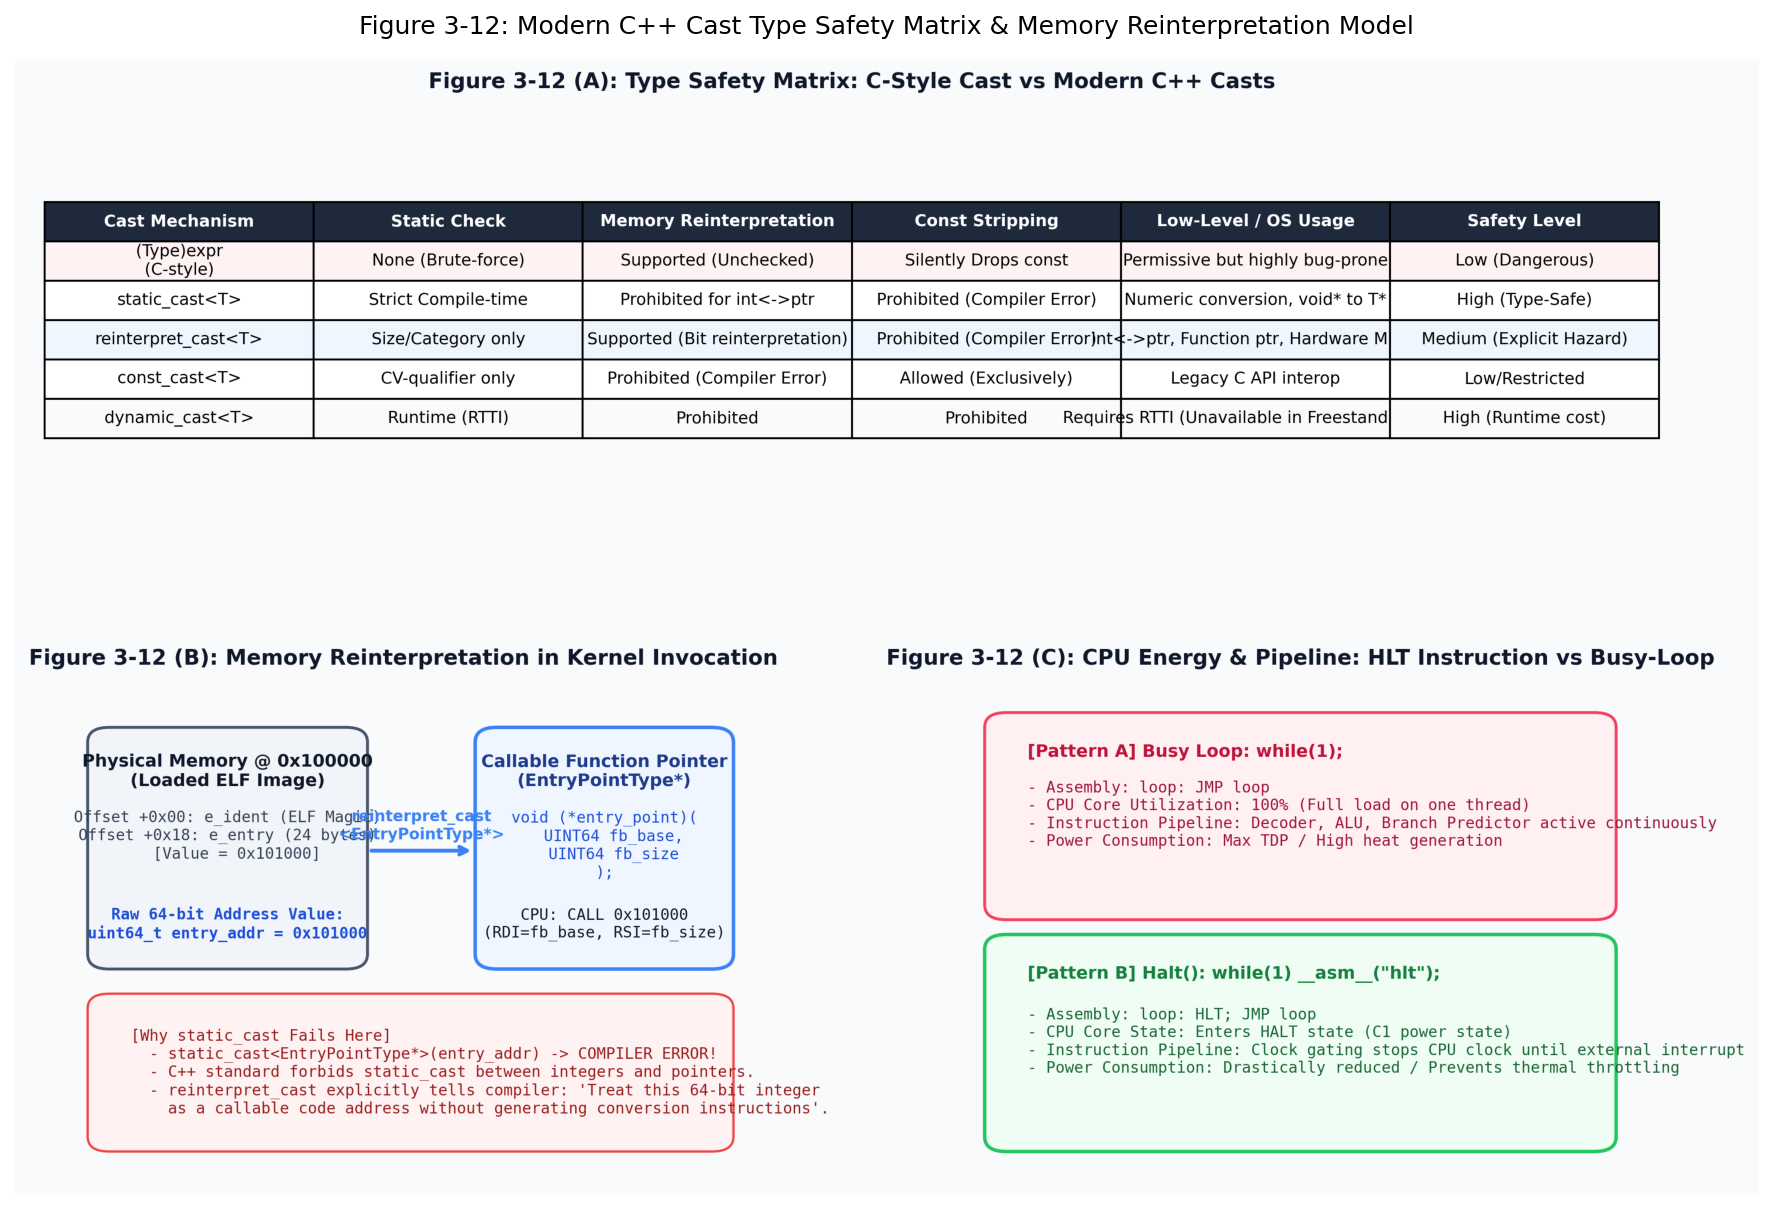

In [5]:
# === C++ 4大キャスト型安全性マトリクスとメモリ再解釈モデル (fig3_12) ===
import os
import matplotlib.pyplot as plt
from PIL import Image
from common import plot_pointer_casts_type_safety_memory

target_dir = "3/result" if os.path.exists("3/result") else "result"
fig12_path = plot_pointer_casts_type_safety_memory(f"{target_dir}/fig3_12_pointer_casts_type_safety_memory.png")
print("Saved figure to:", fig12_path)

plt.figure(figsize=(15, 10), dpi=150)
img = Image.open(fig12_path)
plt.imshow(img)
plt.axis("off")
plt.title("Figure 3-12: Modern C++ Cast Type Safety Matrix & Memory Reinterpretation Model", fontsize=12, pad=12)
plt.show()


## 5. コラム 3.2: ポインタのキャスト（Cスタイルキャストの危険性と C++ 4大キャスト）

### 5.1 C言語スタイルキャスト `(Type)expression` の潜在的危険性
C言語では、以下のように括弧で型名を囲むだけで、あらゆるポインタや変数を別の型へと変換できます：

```c
// C言語スタイルキャスト
typedef void EntryPointType(UINT64, UINT64);
EntryPointType* entry_point = (EntryPointType*)entry_addr;
```
しかし、Cスタイルキャストには **「何でも力ずくで変換してしまう」** という重大な危険があります：
1. **意図しない const 剥奪**:
   読み込み専用であるはずの `const char*` を誤って `(char*)` にキャストして書き込み、メモリ保護違反を起こしてもコンパイラは一切警告しません。
2. **無関係なポインタの誤キャスト**:
   ポインタの型を間違えて全く無関係な構造体にキャストしてしまっても、コンパイルが通ってしまいます。
3. **検索性の悪さ**:
   コードベース内でキャストを行っている箇所を探そうとしても、単なる丸括弧 `(int)` や `(char*)` は通常の演算式や関数プロトタイプと区別がつかず、`grep` での監査が困難です。

---

### 5.2 モダン C++ の 4 大キャスト演算子
C++ では、キャストの目的・リスク・変換規則に応じて、以下の 4 つの明示的キャスト演算子が導入されました：

| キャスト演算子 | 構文 | 許可される変換 | 禁止される変換 | 低レイヤ / OS自作における役割 |
|---|---|---|---|---|
| **`static_cast`** | `static_cast<T>(e)` | 数値型の相互変換、`void*` から具象ポインタへの復元、継承関係のアップ/ダウンキャスト | 整数 ⇄ ポインタ間の変換、無関係なポインタ間の変換、`const` 剥奪 | 通常の型安全な変換。コンパイル時チェックが厳格。 |
| **`reinterpret_cast`** | `reinterpret_cast<T>(e)` | 整数 ⇄ ポインタ間の変換、異なるポインタ型同士のビット再解釈 | `const` 属性の剥奪 | **低レイヤ・OS開発の絶対的主役**。物理アドレスから関数ポインタやMMIO構造体への変換。 |
| **`const_cast`** | `const_cast<T>(e)` | `const` や `volatile` 属性の付与および剥奪のみ | 型自体の変更（整数 ⇄ ポインタ等） | レガシーC APIに `const` 変数を渡す際の一時的な解除。 |
| **`dynamic_cast`** | `dynamic_cast<T>(e)` | 多相クラス（仮想関数を持つクラス）の安全なダウンキャスト（実行時型チェック RTTI） | 仮想関数を持たないクラス、整数・ポインタ変換 | **Freestanding カーネルでは原則使用不可**（RTTI テーブルが必要なため）。 |

### 5.3 OS 自作における `reinterpret_cast` の不可欠性
カーネルエントリポイントを呼び出す処理を見てみましょう：

```cpp
// 64ビット整数として取得したエントリポイントアドレス
uint64_t entry_addr = *(uint64_t*)(kernel_base_addr + 24);

// 1. static_cast を試みると...
auto entry_fn = static_cast<EntryPointType*>(entry_addr);
// -> コンパイルエラー！ error: invalid 'static_cast' from type 'uint64_t' to type 'void (*)(uint64_t, uint64_t)'

// 2. reinterpret_cast を使用すると...
auto entry_fn = reinterpret_cast<EntryPointType*>(entry_addr);
// -> コンパイル成功！
```
`static_cast` は「整数とポインタは概念上全く異なる存在である」と判断し、バグを防ぐために変換を拒否します。
しかし、OS 自作の世界では **「メモリの特定アドレス `0x101000` にある機械語関数を呼び出す」「物理アドレス `0x80000000` にある MMIO レジスタを構造体として読み書きする」** というハードウェア直結の操作が日常茶飯事です。

`reinterpret_cast` は、コンパイラに対して：
> **「私は自分が何をしているか完全に理解している。この 64 ビット整数が表すビット列を、変換コードを生成することなく、そのまま関数ポインタとして再解釈せよ」**

と明示的に宣言する強力な武器なのです。


In [6]:
# === Python による PointerCastSimulator とキャスト安全性マトリクス検証 ===
from common import PointerCastSimulator, CppCastKind

test_cases = [
    ("uint64_t", "void (*)(uint64_t, uint64_t)", CppCastKind.STATIC_CAST),
    ("uint64_t", "void (*)(uint64_t, uint64_t)", CppCastKind.REINTERPRET_CAST),
    ("uint64_t", "void (*)(uint64_t, uint64_t)", CppCastKind.C_STYLE_CAST),
    ("void*", "EFI_FILE_INFO*", CppCastKind.STATIC_CAST),
    ("const char*", "char*", CppCastKind.STATIC_CAST),
    ("const char*", "char*", CppCastKind.CONST_CAST),
]

print(f"{'Source -> Target Type':<42} | {'Cast Operator':<18} | {'Legal?':<8} | {'Explanation / Constraint'}")
print("-" * 110)
for src, tgt, kind in test_cases:
    res = PointerCastSimulator.analyze(src, tgt, kind)
    legal_str = "LEGAL" if res.is_legal else "REJECTED"
    desc = res.compile_error_reason if not res.is_legal else res.low_level_usage
    print(f"{src + ' -> ' + tgt:<42} | {kind.name:<18} | {legal_str:<8} | {desc}")


Source -> Target Type                      | Cast Operator      | Legal?   | Explanation / Constraint
--------------------------------------------------------------------------------------------------------------
uint64_t -> void (*)(uint64_t, uint64_t)   | STATIC_CAST        | REJECTED | error: invalid 'static_cast' from integer type to function pointer type
uint64_t -> void (*)(uint64_t, uint64_t)   | REINTERPRET_CAST   | LEGAL    | カーネルエントリポイント呼び出し (entry_point = reinterpret_cast<EntryPointType*>(entry_addr)) の絶対標準。
uint64_t -> void (*)(uint64_t, uint64_t)   | C_STYLE_CAST       | LEGAL    | コンパイルは通るが、const性の誤消失や危険な型変換を静的に警告しないため非推奨。
void* -> EFI_FILE_INFO*                    | STATIC_CAST        | LEGAL    | void* バッファから具象構造体ポインタへの復元 (static_cast 推奨)。
const char* -> char*                       | STATIC_CAST        | REJECTED | error: cast casts away const qualifier
const char* -> char*                       | CONST_CAST         | LEGAL    | レガシーC API等に渡すために const 修飾を一時的に外す用途。


In [7]:
# === C++20 スタンドアロン検証コード (src/ch03/error_handling_sim.cpp) のコンパイル & 実行 ===
import subprocess

print("=== 1. g++ -std=c++20 によるコンパイルと静的型安全性チェック ===")
compile_cmd = [
    "g++", "-std=c++20", "-O2", "-Wall", "-Wextra",
    "src/ch03/error_handling_sim.cpp",
    "-o", "bin_error_handling_sim"
]
comp_res = subprocess.run(compile_cmd, capture_output=True, text=True)
if comp_res.returncode != 0:
    print("❌ コンパイル失敗:\n", comp_res.stderr)
else:
    print("✅ コンパイル成功！ (static_assert による型チェック全件パス)\n")
    print("=== 2. シミュレーションバイナリの実行 ===")
    run_res = subprocess.run(["./bin_error_handling_sim"], capture_output=True, text=True)
    print(run_res.stdout)
    if os.path.exists("bin_error_handling_sim"):
        os.remove("bin_error_handling_sim")


=== 1. g++ -std=c++20 によるコンパイルと静的型安全性チェック ===


✅ コンパイル成功！ (static_assert による型チェック全件パス)

=== 2. シミュレーションバイナリの実行 ===
Running C++20 MikanOS Chapter 3.6 Verification Suite
[Test 1] EFI_STATUS Arithmetic & EFI_ERROR Macro...
  -> PASSED: EFI_STATUS 64-bit mask and signed logic verified.
[Test 2] Bootloader Nominal Pipeline...
  -> PASSED: Full nominal boot pipeline succeeded.
[Test 3] Graceful Degradation (memmap Open Failure)...
  -> PASSED: Graceful degradation continues boot successfully.
[Test 4] Fatal Error Pipeline Halt...
  -> PASSED: Fatal missing kernel halts boot gracefully.
[Test 5] C++ Cast Type Safety Rules...
  -> PASSED: Static & reinterpret cast constraints verified at compile-time.
ALL C++20 Chapter 3.6 VERIFICATIONS PASSED!



## 6. 本節のまとめと確認演習問題・次節への展望

### 6.1 本節の重要概念チェックリスト
- [x] **サイレントクラッシュの撲滅**: すべての UEFI 呼び出しでステータスを即時判定し、原因究明を可能にする。
- [x] **`EFI_STATUS` 64ビット構造**: Bit 63 (MSB) が 1 ならエラー（`0x8000000000000000ULL`）、0 なら成功または警告。
- [x] **`EFI_ERROR` の 2の補数数理**: `((INTN)status) < 0` により、CPU の符号フラグ（SF）を利用して 1クロックで高速判定。
- [x] **`%r` 書式指定子**: EDK II `Print` により、16進エラーコードを人間可読な文字列（`Not Found` 等）に展開。
- [x] **Graceful Degradation（優雅な縮退）**: 補助的ファイル `\memmap` のオープン失敗は無視し、必須のカーネル起動を継続する。
- [x] **`HLT` 特権命令と CPU 省電力**: ビジーループ `while(1);` による 100% 負荷・過熱を防ぎ、C1 ステートで割り込みを待機。
- [x] **C++ 4大キャストの使い分け**:
  - `static_cast`: 型安全な標準変換（整数 ⇄ ポインタは禁止）。
  - `reinterpret_cast`: 物理アドレスから関数ポインタ等へのビット再解釈（低レイヤの武器）。
  - `const_cast`: `const` 属性の剥奪専用。

---

### 📝 自己採点確認演習問題

#### 問題 1: `EFI_STATUS` の判定式
64ビット環境において、変数 `status` に `0x800000000000000E`（`EFI_NOT_FOUND`）が格納されている。
このとき、以下の C 言語式の評価結果として正しいものを選択せよ。
- 式: `((int64_t)status) < 0`
- 選択肢:
  - (A) `false` (0x8000... は正の巨大な数であるため)
  - (B) `true` (最上位ビットが 1 であり、符号付き 64ビット整数として負の値となるため)
  - (C) コンパイルエラーとなる

<details><summary>正解と解説</summary>

**正解: (B)**
最上位ビット（Bit 63）が 1 の場合、2の補数表現において値は必ず負数となります。したがって `((int64_t)status) < 0` は `true` となり、マクロ `EFI_ERROR(status)` はエラーと判定します。
</details>

#### 問題 2: ポインタキャストの文法制約
64ビット整数 `uint64_t entry_addr` をカーネルエントリポイント関数ポインタ `void (*entry_point)(uint64_t, uint64_t)` に変換したい。
モダン C++ において正しいキャスト記述はどれか？
- 選択肢:
  - (A) `entry_point = static_cast<EntryPointType*>(entry_addr);`
  - (B) `entry_point = dynamic_cast<EntryPointType*>(entry_addr);`
  - (C) `entry_point = reinterpret_cast<EntryPointType*>(entry_addr);`
  - (D) `entry_point = const_cast<EntryPointType*>(entry_addr);`

<details><summary>正解と解説</summary>

**正解: (C)**
C++ 標準規格において、整数とポインタ間の直接変換は `static_cast` では禁止されておりコンパイルエラーとなります。ビット表現をそのまま再解釈する `reinterpret_cast` を使用するのが正解です。
</details>

---

### 🚀 次節への展望: 3.7 ポインタ入門(2)：ポインタとアセンブリ言語
エラー処理と型安全なポインタキャストを身につけた私たちは、ブートローダからカーネルへの引数引き渡しを完璧に理解しました。
次節 **3.7「ポインタ入門(2)：ポインタとアセンブリ言語」** では、私たちが日常的に書いているポインタ操作（ポインタの加算・間接参照・アロー演算子）が、x86-64 アセンブリ命令（`MOV`, `LEA`, アドレス修飾モード）にどのようにコンパイルされるのかを逆アセンブル解析を通じて機械語レベルで徹底的に解明します！
